In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
import scipy as scipy
import seaborn as sns

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Exercise

# Getting the data

In [2]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True)

The keys of the object are:

In [3]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

Let's get a bit acquainted with the data

In [4]:
print(data['DESCR'][:1300])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In this exercise we will stick to the original target variable. Thus, the first task is to divide the data into a training set and a test set. Remember, the latter represents our future unseen examples

In [5]:
X_train, X_test, y_train, y_test = train_test_split(data['data'], data['target'], random_state=0)
print("Number of data points in training set and test set, respectively: {} and {}".format(X_train.shape[0], 
                                                                                          X_test.shape[0]))

Number of data points in training set and test set, respectively: 15480 and 5160


# A first k-NN attempt at a model

In [6]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors=5)

Learn the model, which is this case simply means storing the training data

In [7]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [8]:
print("Model score on test set: {}".format(knn.score(X_test, y_test)))

Model score on test set: 0.14547754686032732


*Note again:* Accruracy is measured by the R^2 coefficient defined as (1 - u/v), where 
 * u is the residual sum of squares ((y_true - y_pred)^2).sum() 
 * v is the total sum of squares ((y_true - y_true.mean())^2).sum().
 
 The values are between 0 and 1, where higher is better.

### *Exercise:* 
* Calculate the performance of the model on the training data
* Try adusting the number of neighbors and see what impact is has on the two scores

# A second k-NN attempt at a model

Let's first take a slightly closer look at our data.

In [9]:
data_df = pd.DataFrame(X_train, columns=data['feature_names'])
data_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000
mean,3.874641,28.629264,5.432519,1.095766,1426.281137,3.037852,35.627119,-119.566138
std,1.894656,12.599829,2.533705,0.493023,1144.524906,6.649475,2.138223,2.006152
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.750000,32.540000,-124.350000
25%,2.569850,18.000000,4.454109,1.005735,785.000000,2.428571,33.930000,-121.800000
50%,3.549850,29.000000,5.234243,1.048611,1167.000000,2.818463,34.250000,-118.490000
75%,4.750000,37.000000,6.055028,1.100000,1724.000000,3.282564,37.710000,-118.000000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,599.714286,41.950000,-114.310000


A box plot can also provide a quick overview:

<Axes: >

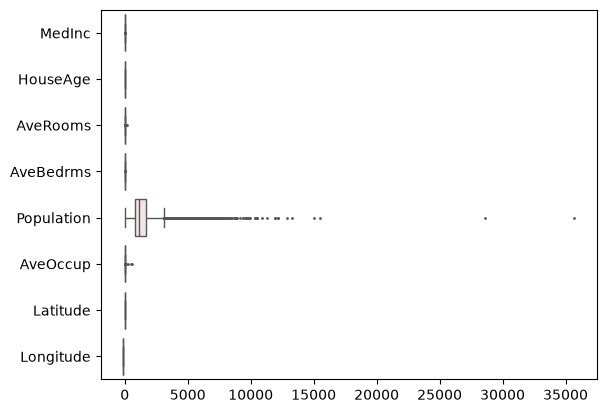

In [10]:
sns.boxplot(data=data_df, palette="vlag", orient='h',fliersize=1)

From the table and the plot we can see some potential issues with the data. Specifically, the scales of some of the features vary quite a lot. For example, the mean of 'Population' is 1426.28 but for 'AveBedrms' it is 1.096. As we saw on the slides, standard distance measures can have a hard time dealing with this. Thus, we resort to normalization (in this case Z-score): 

$$ \mathit{normalized(F)} = \frac{F-\mathit{mean}(F)}{\mathit{std}(F)}$$

Note that below:
* we only use data from the training set when performing the normalization
* the suffix '_n' added to the variables indicates that the features have been normalized.

In [11]:
X_train_n = (X_train-X_train.mean(axis=0))/X_train.std(axis=0)
X_test_n = (X_test-X_train.mean(axis=0))/X_train.std(axis=0)

The result of the normalization

<Axes: >

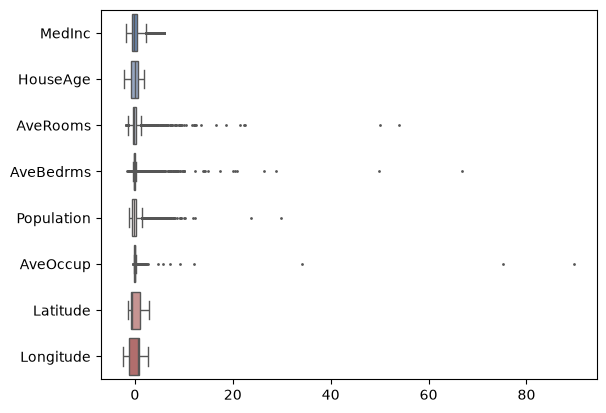

In [12]:
sns.boxplot(data=pd.DataFrame(X_train_n, columns=data['feature_names']), palette="vlag", orient='h',fliersize=1)

Now fit the model to the transformed dataset and score the test set

In [13]:
knn.fit(X_train_n, y_train)
print("Model score on Z-score normalized test set: {}".format(knn.score(X_test_n, y_test)))

Model score on Z-score normalized test set: 0.687694265351535


### *Exercise*: 
* Try making a min-max normalization of the data:
$$ \mathit{normalized(F)} = \frac{F-\mathit{min}(F)}{\mathit{max}(F)-\mathit{min}(F)}$$
* Make a boxplot of the normalized data and compare with the plot obtained from Z-score normalization
* Learn a kNN model and fit it to the new data. Is there a difference in score compared to what was achived using Z-score normalization? Why could that be the case?

# A third kNN model

The data analysis so far has only focused on the individual variables. Let's now look at the interaction between the variables.

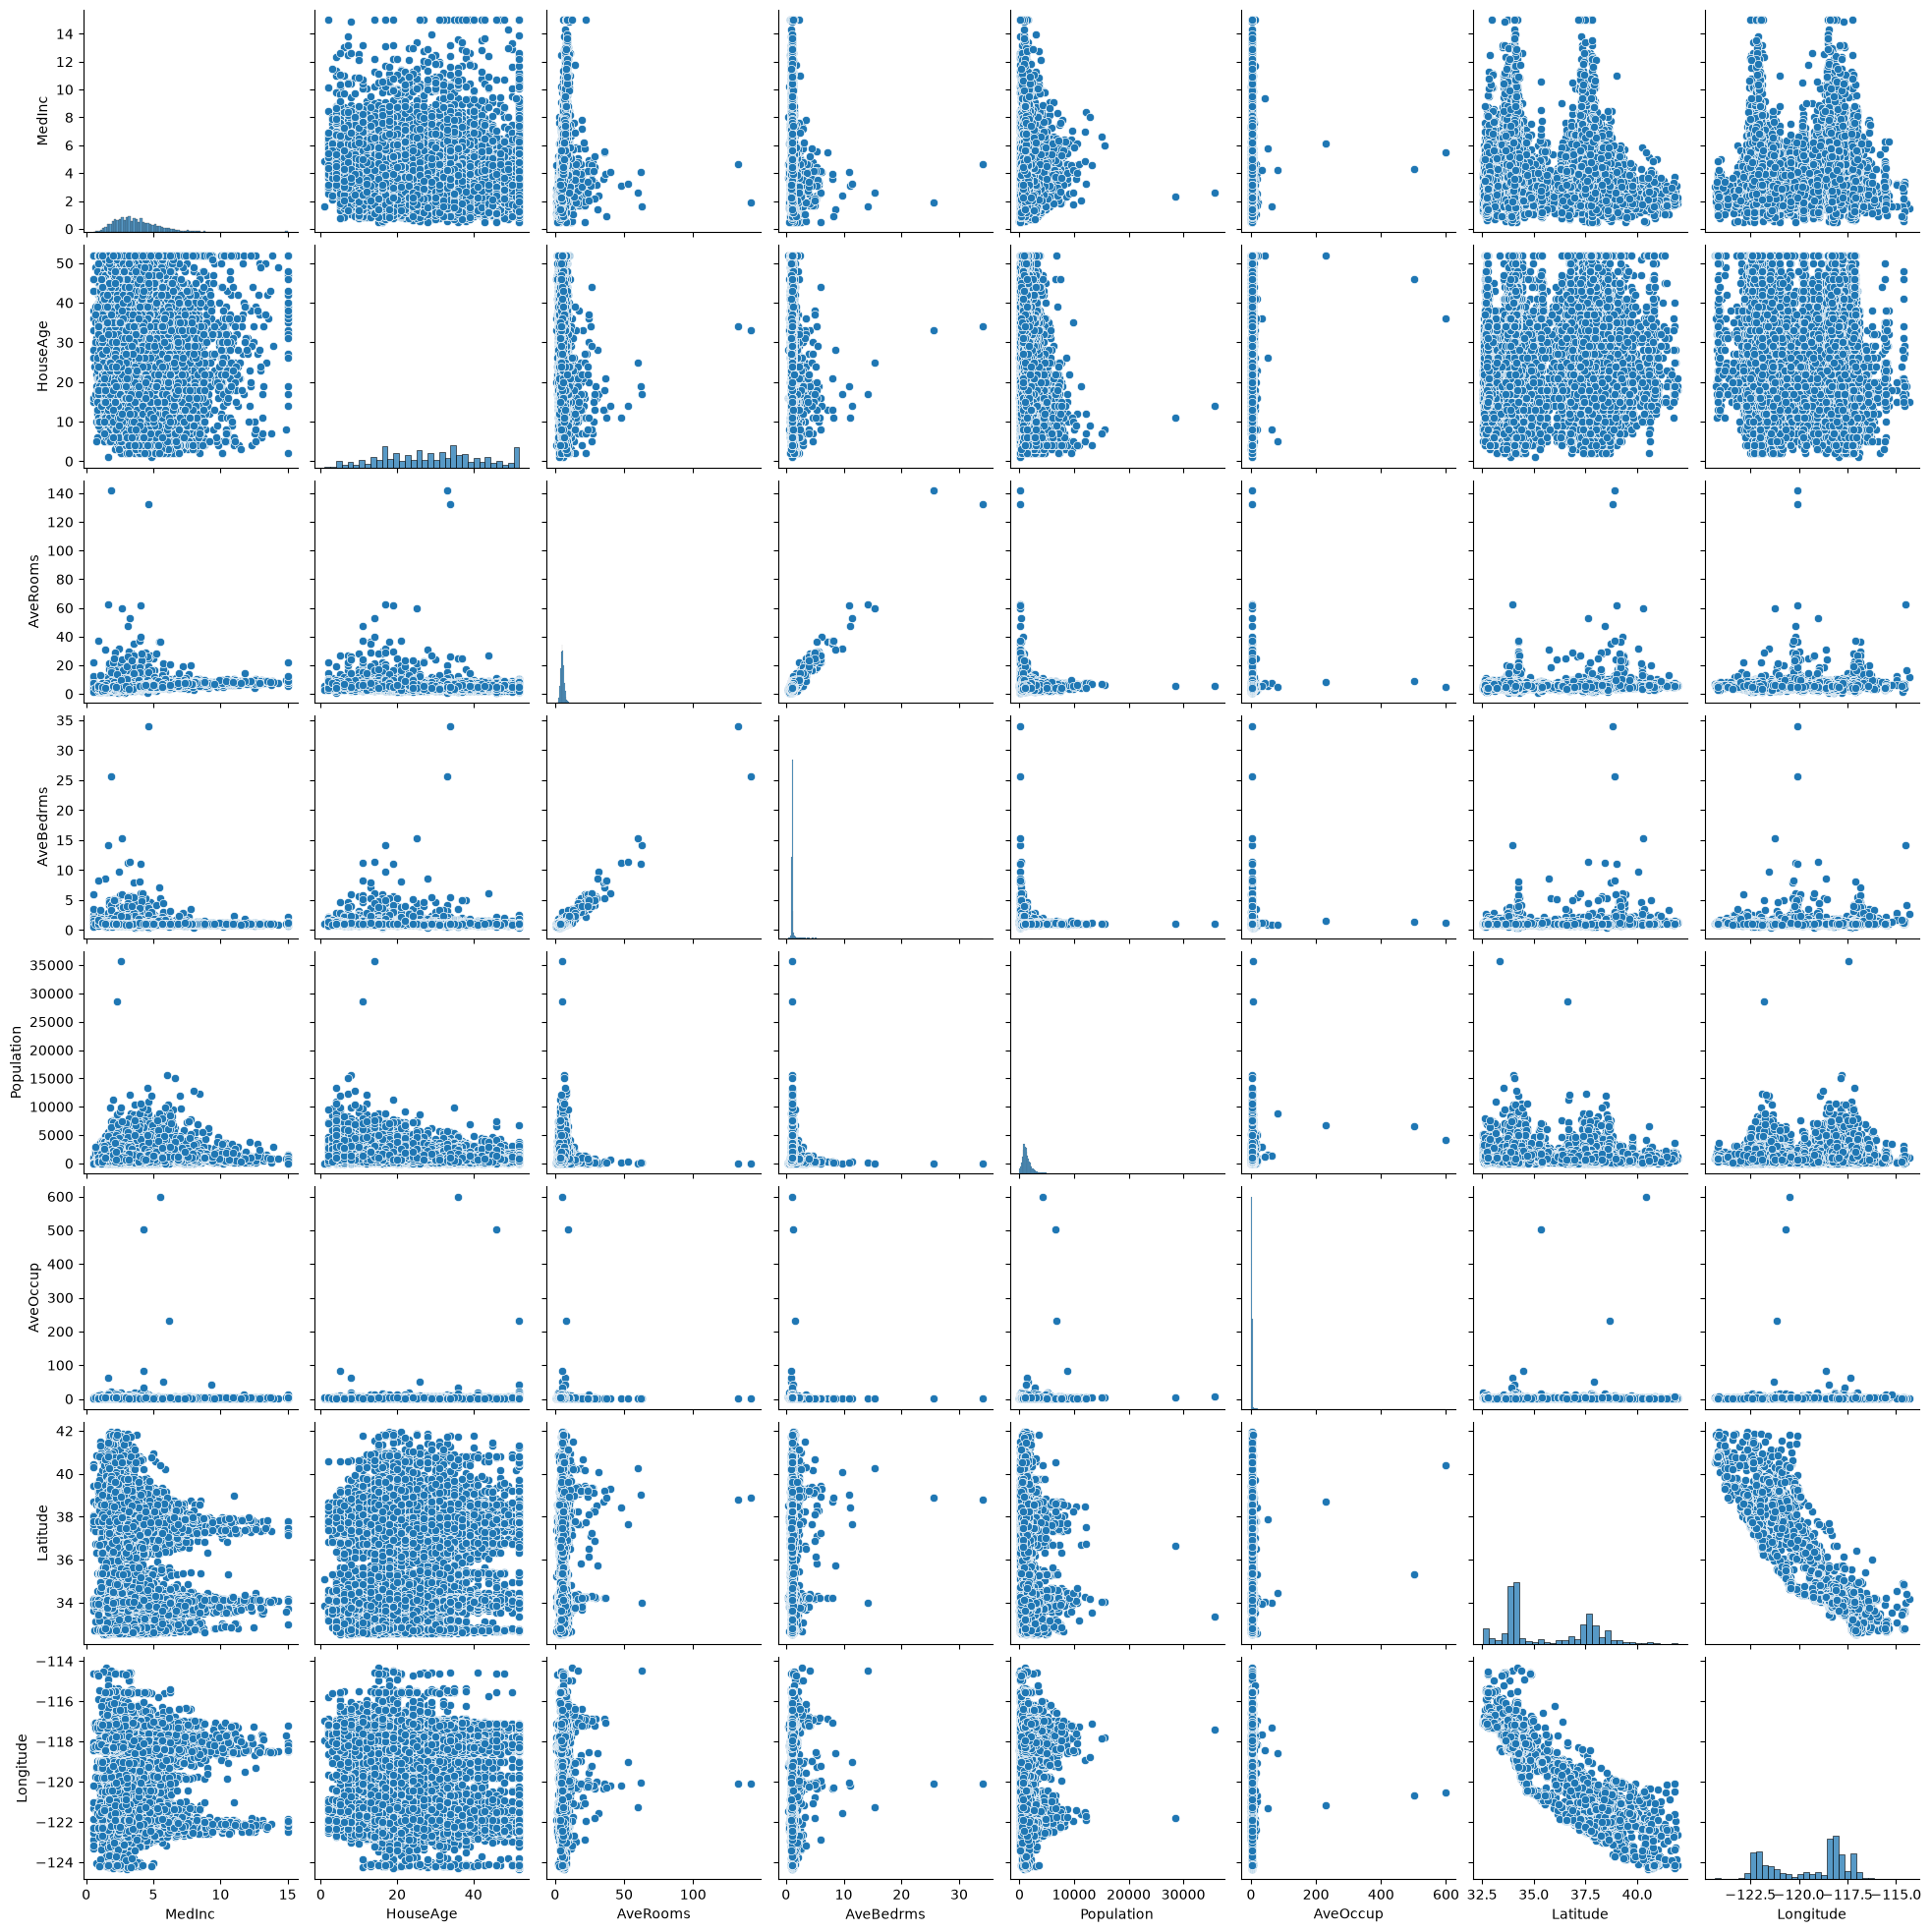

In [14]:
sns.pairplot(data_df)

The covariance matrix captures some of the variability in the data. We can see this by plotting it as a heatmap

<Axes: >

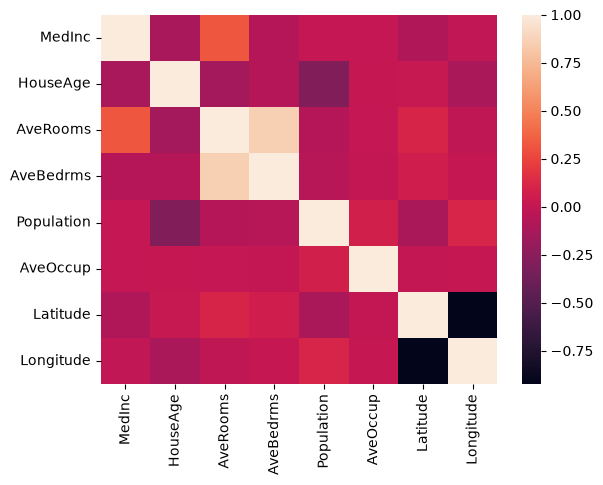

In [15]:
train_cov = np.cov(X_train_n, rowvar=False)
sns.heatmap(train_cov, 
        xticklabels=data['feature_names'],
        yticklabels=data['feature_names'])


The joint variability of the variables is not reflected in the Euclidean distance measure used so far (c.f. Slide 7). We may try to account for this variability using the Mahalanobis distance measure.

In [16]:
# We need to supply the Mahalanobis distance with the data covariance matrix  
knn = KNeighborsRegressor(n_neighbors=5, metric="mahalanobis", metric_params={'V': train_cov})

### *Exercise:*
* Fit the newly specified model (that relies on the Mahalanobis distance) using both the original data and the normalized data
* Evaluate the models with different number of neighbors and compare to the results previously obtained